In [1]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

from agfn.modules import create_agfn, ExpertType, ElicitationStrategy
from agfn.gym import LogReward

from agfn.commons import topk_numpy

torch.manual_seed(42)

In [2]:
device = "cpu"
assert device == "cpu", "Currently, only CPU is supported"

In [3]:
#data_path = "data/chain4_dat01.csv"
# data_path = "data/collfork_dat01.csv"
data_path = "data/sachs/sachs.csv"
data = pd.read_csv(data_path)
data = torch.tensor(data.values, dtype=torch.get_default_dtype(), device=device)

def create_adj(data_path: str, num_nodes: int) -> torch.Tensor:
    match data_path:
        case "data/chain4_dat01.csv":
            # a -> b -> c -> d
            adj = torch.zeros(num_nodes, num_nodes)
            adj[0, 1] = 1
            adj[1, 2] = 1
            adj[2, 3] = 1
        case "data/collfork_dat01.csv":
            # vars = [W, X, Y, Z]
            # X -> Z <-> Y <- W
            # X <-> W -> Z
            adj = torch.zeros(num_nodes, num_nodes)
            # W (0), X (1), Y (2), Z (3)
            # X -> Z: 1 -> 3
            adj[1, 3] = 1
            # Z <-> Y: 3 <-> 2
            adj[3, 2] = 1
            adj[2, 3] = 1
            # Y <- W: 2 <- 0
            adj[0, 2] = 1
            # X <-> W: 1 <-> 0
            adj[1, 0] = 1
            adj[0, 1] = 1
            # W -> Z: 0 -> 3
            adj[0, 3] = 1
        case "data/sachs5/sachs5.csv":
            # vars = [mek,pip3,pka,pkc,jnk]
            # mek <- pka -> jnk
            # pka <- pkc -> mek
            # pkc -> jnk
            adj = torch.zeros(num_nodes, num_nodes)
            # mek (0), pip3 (1), pka (2), pkc (3), jnk (4)
            # mek <- pka: 0 <- 2 = 2 -> 0 
            adj[2,0] = 1
            # pka -> jnk: 2 -> 4
            adj[2,4] = 1
            # pka <- pkc: 2 <- 3 = 3 -> 2
            adj[3,2] = 1
            # pkc -> mek: 3 -> 0
            adj[3,0] = 1
            # pkc -> jnk: 3 -> 4
            adj[3,4] = 1
        
        case "data/sachs7/sachs7.csv":
            # vars = [mek,plc,pip2,pip3,pka,pkc,jnk]
            # mek <- pka -> jnk
            # pka <- pkc -> mek
            # pkc -> jnk
            # pip3 <- plc -> pip2
            # pip3 -> pip2
            adj = torch.zeros(num_nodes, num_nodes)
            # mek (0), plc (1), pip2 (2), pip3 (3), pka (4), pkc (5), jnk (6)
            # mek <- pka: 0 <- 4 = 4 -> 0 
            adj[4,0] = 1
            # pka -> jnk: 4 -> 6
            adj[4,6] = 1
            # pka <- pkc: 4 <- 5 = 5 -> 4
            adj[5,4] = 1
            # pkc -> mek: 5 -> 0
            adj[5,0] = 1
            # pkc -> jnk: 5 -> 6
            adj[5,6] = 1
            # plc -> pip3: 1 -> 3
            adj[1,3] = 1
            # plc -> pip2: 1 -> 2
            adj[1,2] = 1
            # pip3 -> pip2: 3 -> 2
            adj[3,2] = 1
        
        case "data/sachs/sachs.csv":
            # vars = [raf,mek,plc,pip2,pip3,erk,akt,pka,pkc,p38,jnk]
            # mek <- pka -> jnk
            # pka <- pkc -> mek
            # pkc -> jnk
            # pip3 <- plc -> pip2
            # pip3 -> pip2
            # raf -> mek
            # pka -> raf
            # pkc -> raf
            # pka -> p38
            # pkc -> p38
            # erk -> akt
            # mek -> erk
            # pka -> erk
            # pka -> akt
            adj = torch.zeros(num_nodes, num_nodes)
            # raf (0), mek (1), plc (2), pip2 (3), pip3 (4), erk (5), akt (6), pka (7), pkc (8), p38(9), jnk (10)
            # mek <- pka: 1 <- 7 = 7 -> 1 
            adj[7,1] = 1
            # pka -> jnk: 7 -> 10
            adj[7,10] = 1
            # pka <- pkc: 7 <- 8 = 8 -> 7
            adj[8,7] = 1
            # pkc -> mek: 8 -> 1
            adj[8,1] = 1
            # pkc -> jnk: 8 -> 10
            adj[8,10] = 1
            # plc -> pip3: 2 -> 4
            adj[2,4] = 1
            # plc -> pip2: 2 -> 3
            adj[2,3] = 1
            # pip3 -> pip2: 4 -> 3
            adj[4,3] = 1
            # raf -> mek: 0 -> 1
            adj[0,1] = 1
            # pka -> raf: 7 -> 0
            adj[7,0] = 1
            # pkc -> raf: 8 -> 0
            adj[8,0] = 1
            # pka -> p38: 7 -> 9
            adj[7,9] = 1
            # pkc -> p38: 8 -> 9
            adj[8,9] = 1
            # erk -> akt: 5 -> 6
            adj[5,6] = 1            
            # mek -> erk: 1 -> 5
            adj[1,5] = 1            
            # pka -> erk: 7 -> 5
            adj[7,5] = 1
            # pka -> akt: 7 -> 6
            adj[7,6] = 1

    return adj

num_nodes = data.shape[1]
adj = create_adj(data_path, num_nodes)

In [4]:
log_reward = LogReward(data)
agfn = create_agfn(
    #ExpertType.LLM_ORACLE, 
    ExpertType.LLM_ORACLE_SACHS,
    ElicitationStrategy.LARGEST_ENTROPY, 
    log_reward, 
    #expert_kwargs={"adj": adj, "num_nodes": num_nodes, "llm_name": "ollama_chat/deepseek-r1:8b"},
    expert_kwargs={"adj": adj, "num_nodes": num_nodes, "llm_name": "openai/gpt-4o"},
    gflownet_kwargs={"hidden_dim": 128, "num_layers": 2, "criterion": "tb"}
)

In [ ]:
agfn.temperature_warmup()
log_z_values = agfn.train(num_epochs=500)

In [ ]:
#get shd before feedback

samples, log_scores = agfn.sample(num_samples=100, batch_size=32, progress_bar=True, log_reward_coef=0.1)

largest_reward_samples = topk_numpy(log_scores, k=25)

adjacency_matrices = np.unique(samples[largest_reward_samples], axis=0)

shd = [np.abs(amat - adj.cpu().numpy()).sum() for amat in adjacency_matrices]
avg_shd = [np.mean(shd),np.std(shd)]

print(avg_shd)

In [ ]:
agfn.eval_mode()
agfn.reset_queries()
llm_rate = agfn.feedback_loop(expert_returns_confidence=True)

In [25]:
graphs, log_scores = agfn.sample(num_samples=100, batch_size=32, progress_bar=True, log_reward_coef=0.1)

100%|████████████████████████████████████████████████████████████████████████████████| 100/100 [00:29<00:00,  3.43it/s]


In [28]:
def get_best_scores(log_scores):
    scores=np.sort(log_scores)[::-1]

    if len(scores) == 1:
        return scores
        
    best = scores[0]        
    best_scores = [best]
    i = 1
    
    while(np.abs(best - scores[i]) <= 0.005):
        best_scores.append(scores[i])
        i += 1
    
    return best_scores        

## Reset the queries and compute the evolving SHD

In [ ]:
agfn.reset_queries()

from agfn.gym import MAG
import sklearn
from sklearn.metrics import roc_auc_score

import networkx as nx

g_shds = []
d_shds = []

data_true_PAG,graph_true_PAG = get_true_PAGs(11)

#for i in range(1):
for r in range(agfn.expert.num_node_pairs):
    agfn.feedback_loop(num_feedbacks=1,expert_returns_confidence=True)

    samples, log_scores = agfn.sample(num_samples=1000, batch_size=32, progress_bar=True, log_reward_coef=1/(r + 1))

    #best_score = float(log_scores[topk_numpy(log_scores, k=1)])
    
    scores=get_best_scores(log_scores)
        
    top_scores = topk_numpy(log_scores, k=len(scores))
    #print(f'top scores: {scores}\n')
    
    #top_equivalence_class = [np.unique(samples[i], axis=0) for i in top_scores]
    top_equivalence_class = np.unique(samples[top_scores], axis=0)
    
    print(f'eq. class size: {len(top_equivalence_class)}\n graphs: \n{top_equivalence_class}\n')
    #nx.draw_networkx(nx.DiGraph(top_equivalence_class[0]), with_labels = True)
    #plt.show()
    
    #graph_shd = np.array([baseline_shd(np.array(adj),amat) for amat in top_equivalence_class])
    #data_shd = np.array([baseline_shd(data_true_PAG,amat) for amat in top_equivalence_class])

    #g_shds.append([graph_shd.min(),graph_shd.max()])
    g_shds.append(baseline_shd(np.array(adj),top_equivalence_class[0]))
    #d_shds.append([data_shd.min(),data_shd.max()])
    #print(f'MIN SHD IS: {np.argmin(graph_shd)}o best-score \n MAX SHD IS: {np.argmax(graph_shd)}o best-score ')



In [1]:
import numpy as np

sachs5 = [[np.int64(12), np.int64(11), np.int64(9), np.int64(7), np.int64(10), np.int64(8), np.int64(6), np.int64(7), np.int64(7), np.int64(6)], [np.int64(14), np.int64(12), np.int64(9), np.int64(7), np.int64(5), np.int64(8), np.int64(7), np.int64(6), np.int64(6), np.int64(5)], [np.int64(14), np.int64(12), np.int64(9), np.int64(8), np.int64(8), np.int64(10), np.int64(6), np.int64(8), np.int64(8), np.int64(7)]]
sachs7 = [[np.int64(20), np.int64(16), np.int64(19), np.int64(15), np.int64(19), np.int64(13), np.int64(15), np.int64(17), np.int64(14), np.int64(14), np.int64(12), np.int64(15), np.int64(12), np.int64(10), np.int64(11), np.int64(10), np.int64(8), np.int64(9), np.int64(10), np.int64(8), np.int64(8)], [np.int64(23), np.int64(22), np.int64(19), np.int64(15), np.int64(15), np.int64(17), np.int64(13), np.int64(17), np.int64(13), np.int64(16), np.int64(18), np.int64(15), np.int64(10), np.int64(13), np.int64(14), np.int64(10), np.int64(10), np.int64(9), np.int64(9), np.int64(9), np.int64(8)], [np.int64(21), np.int64(22), np.int64(15), np.int64(17), np.int64(19), np.int64(17), np.int64(14), np.int64(14), np.int64(15), np.int64(14), np.int64(14), np.int64(12), np.int64(17), np.int64(11), np.int64(10), np.int64(8), np.int64(9), np.int64(8), np.int64(8), np.int64(8), np.int64(7)]]
sachs = [[np.int64(53), np.int64(49), np.int64(42), np.int64(41), np.int64(49), np.int64(45), np.int64(45), np.int64(49), np.int64(38), np.int64(59), np.int64(41), np.int64(42), np.int64(31), np.int64(35), np.int64(39), np.int64(50), np.int64(37), np.int64(47), np.int64(42), np.int64(36), np.int64(42), np.int64(33), np.int64(34), np.int64(43), np.int64(41), np.int64(38), np.int64(35), np.int64(47), np.int64(37), np.int64(38), np.int64(41), np.int64(40), np.int64(30), np.int64(38), np.int64(41), np.int64(31), np.int64(42), np.int64(26), np.int64(27), np.int64(36), np.int64(34), np.int64(41), np.int64(32), np.int64(32), np.int64(35), np.int64(35), np.int64(31), np.int64(37), np.int64(35), np.int64(37), np.int64(31), np.int64(36), np.int64(34), np.int64(41), np.int64(34)], [np.int64(50), np.int64(38), np.int64(56), np.int64(41), np.int64(31), np.int64(54), np.int64(37), np.int64(40), np.int64(39), np.int64(49), np.int64(41), np.int64(43), np.int64(39), np.int64(45), np.int64(44), np.int64(37), np.int64(41), np.int64(44), np.int64(34), np.int64(46), np.int64(45), np.int64(36), np.int64(42), np.int64(40), np.int64(42), np.int64(41), np.int64(46), np.int64(44), np.int64(40), np.int64(49), np.int64(38), np.int64(37), np.int64(31), np.int64(34), np.int64(37), np.int64(27), np.int64(38), np.int64(38), np.int64(32), np.int64(32), np.int64(39), np.int64(35), np.int64(27), np.int64(26), np.int64(34), np.int64(37), np.int64(34), np.int64(37), np.int64(33), np.int64(33), np.int64(36), np.int64(35), np.int64(36), np.int64(34), np.int64(33)], [np.int64(46), np.int64(41), np.int64(50), np.int64(47), np.int64(45), np.int64(47), np.int64(47), np.int64(42), np.int64(39), np.int64(53), np.int64(45), np.int64(34), np.int64(53), np.int64(41), np.int64(50), np.int64(46), np.int64(40), np.int64(52), np.int64(40), np.int64(46), np.int64(43), np.int64(45), np.int64(41), np.int64(48), np.int64(38), np.int64(37), np.int64(45), np.int64(38), np.int64(36), np.int64(36), np.int64(35), np.int64(38), np.int64(39), np.int64(38), np.int64(37), np.int64(32), np.int64(32), np.int64(32), np.int64(37), np.int64(36), np.int64(30), np.int64(32), np.int64(31), np.int64(39), np.int64(31), np.int64(32), np.int64(34), np.int64(33), np.int64(34), np.int64(36), np.int64(34), np.int64(34), np.int64(28), np.int64(35), np.int64(32)]]

sachs5_mean = [np.mean([sachs5[0][i],sachs5[1][i],sachs5[2][i]]) for i in range(len(sachs5[0]))]
sachs5_std = [np.std([sachs5[0][i],sachs5[1][i],sachs5[2][i]]) for i in range(len(sachs5[0]))]

sachs7_mean = [np.mean([sachs7[0][i],sachs7[1][i],sachs7[2][i]]) for i in range(len(sachs7[0]))]
sachs7_std = [np.std([sachs7[0][i],sachs7[1][i],sachs7[2][i]]) for i in range(len(sachs7[0]))]

sachs_mean = [np.mean([sachs[0][i],sachs[1][i],sachs[2][i]]) for i in range(len(sachs[0]))]
sachs_std = [np.std([sachs[0][i],sachs[1][i],sachs[2][i]]) for i in range(len(sachs[0]))]

sachs5_no_feedback = [np.float32(12.666667), np.float32(0.94280905)]
sachs7_no_feedback = [np.float32(23.0), np.float32(4.9665546)]
sachs_no_feedback = [np.float32(53.56), np.float32(5.470503)]

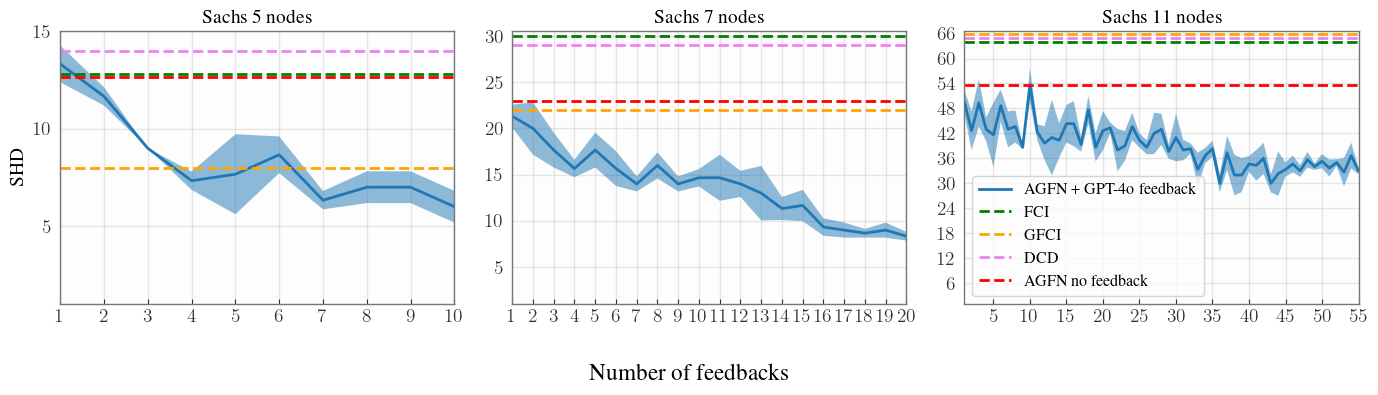

In [6]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.pyplot import MultipleLocator
matplotlib.rcParams.update({
    'font.family' : 'serif',
    'font.size' : 14.0,
    'lines.linewidth' : 2,
    'lines.antialiased' : True,
    'axes.facecolor': 'fdfdfd',
    'axes.edgecolor': '777777',
    'axes.linewidth' : 1,
    'axes.titlesize' : 'medium',
    'axes.labelsize' : 'medium',
    'axes.axisbelow' : True,
    # 'xtick.major.size'     : 0,      # major tick size in points
    # 'xtick.minor.size'     : 0,      # minor tick size in points
    # 'xtick.major.pad'      : 6,      # distance to major tick label in points
    # 'xtick.minor.pad'      : 6,      # distance to the minor tick label in points
    'xtick.color'          : '333333', # color of the tick labels
    'xtick.labelsize'      : 'medium', # fontsize of the tick labels
    'xtick.direction'      : 'in',     # direction: in or out
    'ytick.major.size'     : 0,      # major tick size in points
    'ytick.minor.size'     : 0,      # minor tick size in points
    'ytick.major.pad'      : 6,      # distance to major tick label in points
    'ytick.minor.pad'      : 6,      # distance to the minor tick label in points
    'ytick.color'          : '333333', # color of the tick labels
    'ytick.labelsize'      : 'medium', # fontsize of the tick labels
    'ytick.direction'      : 'in',     # direction: in or out
    'axes.grid' : True,
    'grid.alpha' : 0.3,
    'grid.linewidth' : 1,
    'legend.fancybox' : True,
    'legend.fontsize' : 'Small',
    'figure.figsize' : (2.5, 2.5),
    'figure.facecolor' : '1.0',
    'figure.edgecolor' : '0.5',
    'hatch.linewidth' : 0.1,
    'text.usetex' : True 
    })
plt.rcParams['text.latex.preamble'] = r'\usepackage{times, amsmath, amssymb}'
from matplotlib.ticker import FuncFormatter
def my_formatter(x, pos):
    """Format 1 as 1, 0 as 0, and all values whose absolute values is between
    0 and 1 without the leading "0." (e.g., 0.7 is formatted as .7 and -0.4 is
    formatted as -.4)."""
    val_str = '{:g}'.format(x)
    if np.abs(x) > 0 and np.abs(x) < 1:
        return val_str.replace("0", "", 1)
    else:
        return val_str
def evenly_spaced_ticks(ax, axis='x', n=5): 
    if axis == 'x': 
        max_v = max(ax.get_xlim()) 
    elif axis == 'y': 
        max_v = max(ax.get_ylim())
    else: 
        raise ValueError(axis) 
    tick_positions = [i / (n + 1) * max_v for i in range(1, n + 1)] 
    primitive = ax.xaxis if axis == 'x' else ax.yaxis 
    primitive.set_major_locator(FixedLocator(tick_positions))

major_formatter = FuncFormatter(my_formatter)
from matplotlib.ticker import NullFormatter
from matplotlib.ticker import ScalarFormatter, StrMethodFormatter, MaxNLocator, FixedLocator 

color_to_method = {
    'fci': 'green', 
    'gfci': 'orange', 
    'dcd': 'violet', 
    # 'aci': 'brown', 
    'sortnregress': 'olive' 
}
methods = {
    'fci': {
        5: 12.8, 
        7: 30,
        11: 64,   
    }, 
    'gfci': {
        5: 8, 
        7: 22,
        11: 66,  
    }, 
    'dcd': {
        5: 14, 
        7: 29,
        11: 65,  
    }
}
sachs = {
    5: {'mean': sachs5_mean,
        'std': sachs5_std,
        'axhline': sachs5_no_feedback[0],
        'xlim': 10,
        'ylim': 15},
    7: {'mean': sachs7_mean,
        'std': sachs7_std,
        'axhline': sachs7_no_feedback[0],
        'xlim': 20,
        'ylim': 30.5},
    11: {'mean': sachs_mean,
        'std': sachs_std,
        'axhline': sachs_no_feedback[0],
        'xlim': 55,
        'ylim': 66.5}
}

plt.figure(figsize=(14, 4)) 
c = 1 
for s in sachs: 
    plt.subplot(1, 3, c) 
    values = np.array(sachs[s]['mean'])
    stds = np.array(sachs[s]['std']) 
    xs = np.arange(1,len(sachs[s]['mean'])+1)
    plt.plot(xs, values, label='AGFN + GPT-4o feedback')   

    plt.fill_between(xs, values - stds, values + stds, alpha=.5)  
    #plt.title(dataset if dataset != 'iv' else 'IV') 

    for method in methods: 
        plt.axhline(y=methods[method][s], linestyle='--', c=color_to_method[method], label=method.upper())
        
    plt.axhline(y=sachs[s]['axhline'], linestyle='--', c='red', label='AGFN no feedback')
    
    ax = plt.gca() 

    if c == 3: 
        plt.legend(loc='lower left') 
        ax.xaxis.set_major_locator(MaxNLocator(nbins=sachs[s]['xlim']/5, integer=True)) 
    elif c == 1:
        plt.ylabel('SHD') 
        ax.xaxis.set_major_locator(MaxNLocator(nbins=sachs[s]['xlim'], integer=True)) 
    else:
        ax.xaxis.set_major_locator(MaxNLocator(nbins=sachs[s]['xlim'], integer=True)) 
        
    c += 1
    plt.title(f'Sachs {s} nodes')
        

    ax.yaxis.set_major_locator(MaxNLocator(nbins=sachs[s]['ylim']/5)) 
    plt.xlim([1, sachs[s]['xlim']]) 
    plt.ylim([1, sachs[s]['ylim']]) 
fig = plt.gcf() 
fig.supxlabel('Number of feedbacks') 
plt.tight_layout()
# Check different reliability levels 
plt.savefig('sachs_benchmarks.pdf', bbox_inches='tight') 